# Principal Component Analysis (PCA) with KNN Classification


In [1]:
student_name='\u0905\u092F\u093E\u0928 \u0916\u093E\u0928'
print("STUDENT NAME: ",student_name)

STUDENT NAME:  अयान खान


In [2]:
submited_to='\u0935\u0948\u0936\u093E\u0932\u0940\u0020\u0907\u0902\u0917\u0933\u0947'
print("SUBMITED TO: ",submited_to)

SUBMITED TO:  वैशाली इंगळे


#### IMPORTING LIBRARIES

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from matplotlib.colors import ListedColormap


#### LOADING DATASET

In [4]:
df = pd.read_csv("Wine.csv")
print("Original dataset shape (including target):", df.shape)
print("Dataset shape before PCA (input features):", df.drop(columns="Customer_Segment").shape)
df.head(5)


Original dataset shape (including target): (178, 14)
Dataset shape before PCA (input features): (178, 13)


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1


In [5]:
df["Customer_Segment"].unique()

array([1, 2, 3])

#### DATA ANALYSIS

In [6]:
print("Missing values:")
print(df.isnull().sum())

if(df.duplicated().sum()==0):
  print("\nNo duplicate rows present.")
else:
  print("\nDuplicate rows:", df.duplicated().sum())


Missing values:
Alcohol                 0
Malic_Acid              0
Ash                     0
Ash_Alcanity            0
Magnesium               0
Total_Phenols           0
Flavanoids              0
Nonflavanoid_Phenols    0
Proanthocyanins         0
Color_Intensity         0
Hue                     0
OD280                   0
Proline                 0
Customer_Segment        0
dtype: int64

No duplicate rows present.


#### DEPENDENT AND INDEPENDENT FEATURES

In [7]:
X = df.drop("Customer_Segment", axis=1)
y = df["Customer_Segment"]

print("Input features shape:", X.shape)
print("Output variable shape:", y.shape)

Input features shape: (178, 13)
Output variable shape: (178,)


#### TRAIN / TEST SPLIT AND SCALING


In [8]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)
X_scaled = scaler.transform(X)
print("Dataset shape before PCA:", X_scaled.shape)


Dataset shape before PCA: (178, 13)


In [9]:
print("Training data shape before PCA:", X_train.shape)
print("Testing data shape before PCA:", X_test.shape)


Training data shape before PCA: (142, 13)
Testing data shape before PCA: (36, 13)


In [10]:
knn_before = KNeighborsClassifier(n_neighbors=5)
knn_before.fit(X_train, y_train)
train_pred_before = knn_before.predict(X_train)
test_pred_before = knn_before.predict(X_test)
accuracy_before = accuracy_score(y_test, test_pred_before)
print("KNN before PCA - Training Accuracy:", accuracy_score(y_train, train_pred_before))
print("KNN before PCA - Testing Accuracy:", accuracy_before)
print("\nClassification Report (KNN before PCA):")
print(classification_report(y_test, test_pred_before, zero_division=0))


KNN before PCA - Training Accuracy: 0.9788732394366197
KNN before PCA - Testing Accuracy: 0.9722222222222222

Classification Report (KNN before PCA):
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       1.00      0.93      0.96        14
           3       0.91      1.00      0.95        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



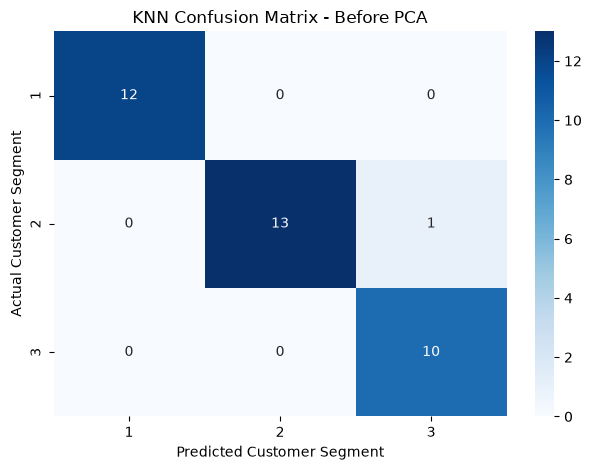

In [11]:
classes = np.sort(y.unique())
sns.heatmap(confusion_matrix(y_test, test_pred_before, labels=classes),
            annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted Customer Segment")
plt.ylabel("Actual Customer Segment")
plt.title("KNN Confusion Matrix - Before PCA")
plt.tight_layout()
plt.show()


#### PRINCIPAL COMPONENT ANALYSIS

In [12]:
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)
X_pca = pca.transform(X_scaled)
print("Dataset shape before PCA:", X.shape)
print("Dataset shape after PCA:", X_pca.shape)
pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"], index=X.index)
pca_df["Customer_Segment"] = y
pca_df.head()


Dataset shape before PCA: (178, 13)
Dataset shape after PCA: (178, 2)


,PC1,PC2,Customer_Segment
0,3.441260,1.455301,1
1,2.280164,-0.208788,1
2,2.648949,1.026536,1
3,3.909025,2.831495,1
4,1.128474,0.868607,1


In [13]:
print("Training data shape after PCA:", X_train_pca.shape)
print("Testing data shape after PCA:", X_test_pca.shape)
print("PCA dataset shape including target:", pca_df.shape)


Training data shape after PCA: (142, 2)
Testing data shape after PCA: (36, 2)
PCA dataset shape including target: (178, 3)


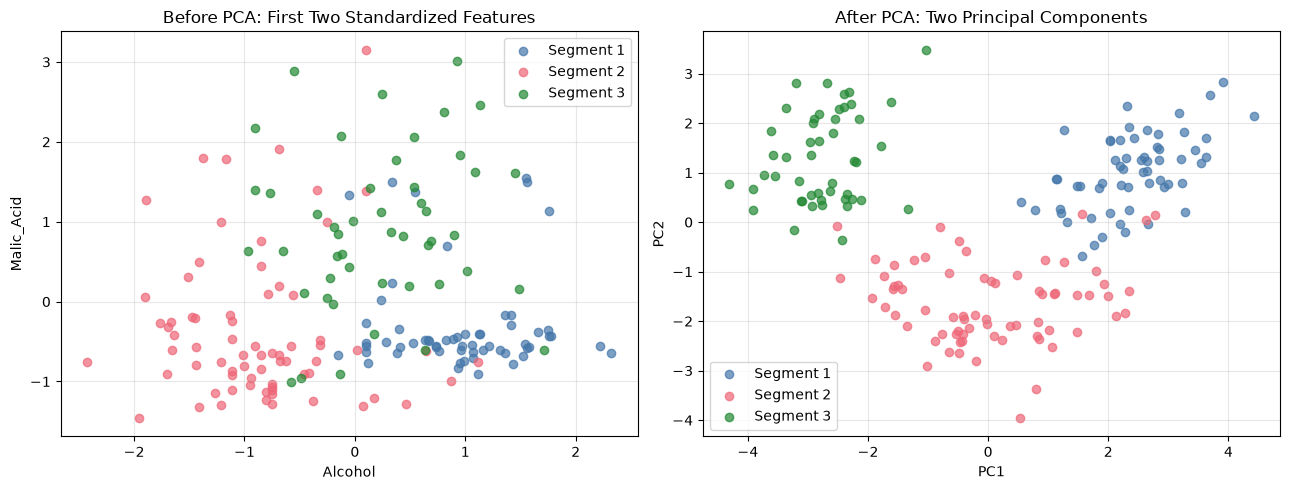

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = ["#4477AA", "#EE6677", "#228833"]
for label, color in zip(classes, colors):
    mask = y.to_numpy() == label
    axes[0].scatter(X_scaled[mask, 0], X_scaled[mask, 1], color=color, label=f"Segment {label}", alpha=0.7)
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], color=color, label=f"Segment {label}", alpha=0.7)
axes[0].set(title="Before PCA: First Two Standardized Features", xlabel=X.columns[0], ylabel=X.columns[1])
axes[1].set(title="After PCA: Two Principal Components", xlabel="PC1", ylabel="PC2")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [15]:
variance_df = pd.DataFrame({
    "Principal Component": ["PC1", "PC2"],
    "Explained Variance Ratio": pca.explained_variance_ratio_
})

print(variance_df)

  Principal Component  Explained Variance Ratio
0                 PC1                  0.357921
1                 PC2                  0.192707


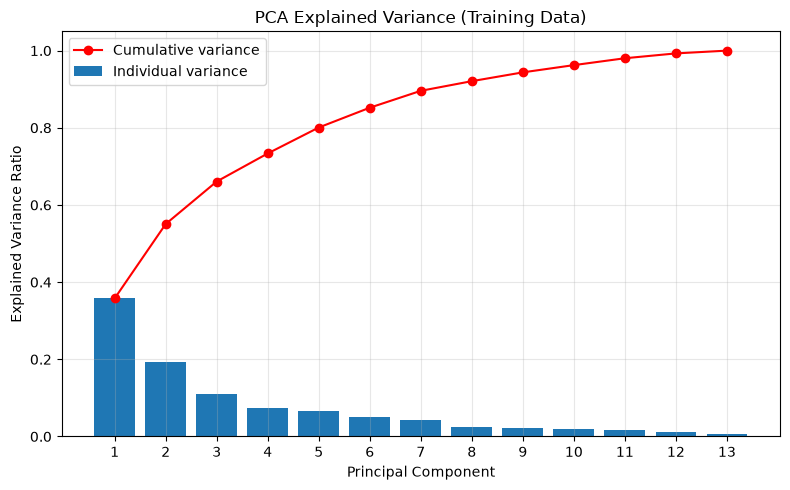

In [16]:
pca_full = PCA().fit(X_train)
ratios = pca_full.explained_variance_ratio_
components = np.arange(1, len(ratios) + 1)
plt.figure(figsize=(8, 5))
plt.bar(components, ratios, label="Individual variance")
plt.plot(components, np.cumsum(ratios), marker="o", color="red", label="Cumulative variance")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Explained Variance (Training Data)")
plt.xticks(components)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [17]:
pca_df.head(5)


,PC1,PC2,Customer_Segment
0,3.441260,1.455301,1
1,2.280164,-0.208788,1
2,2.648949,1.026536,1
3,3.909025,2.831495,1
4,1.128474,0.868607,1


In [18]:
knn_after = KNeighborsClassifier(n_neighbors=5)
knn_after.fit(X_train_pca, y_train)
y_train_pred = knn_after.predict(X_train_pca)
y_test_pred = knn_after.predict(X_test_pca)
accuracy_after = accuracy_score(y_test, y_test_pred)
print("KNN after PCA - Training Accuracy:", accuracy_score(y_train, y_train_pred))
print("KNN after PCA - Testing Accuracy:", accuracy_after)
print("\nClassification Report (KNN after PCA):")
print(classification_report(y_test, y_test_pred, zero_division=0))


KNN after PCA - Training Accuracy: 0.9788732394366197
KNN after PCA - Testing Accuracy: 0.9166666666666666

Classification Report (KNN after PCA):
              precision    recall  f1-score   support

           1       0.92      0.92      0.92        12
           2       0.87      0.93      0.90        14
           3       1.00      0.90      0.95        10

    accuracy                           0.92        36
   macro avg       0.93      0.92      0.92        36
weighted avg       0.92      0.92      0.92        36



In [19]:
print("Predicted classes:", np.unique(y_test_pred))
print("Actual classes:", np.unique(y_test))

Predicted classes: [1 2 3]
Actual classes: [1 2 3]


In [20]:
print("Actual test class distribution:")
print(y_test.value_counts().sort_index())

print("\nPredicted class distribution:")
print(pd.Series(y_test_pred).value_counts().sort_index())

Actual test class distribution:
Customer_Segment
1    12
2    14
3    10
Name: count, dtype: int64

Predicted class distribution:
1    12
2    15
3     9
Name: count, dtype: int64


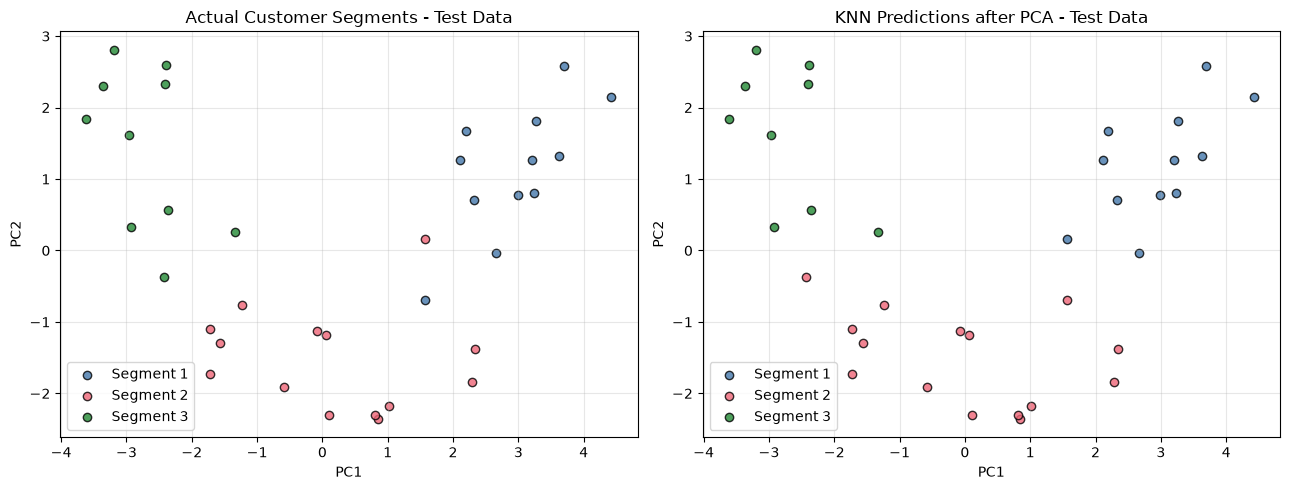

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for label, color in zip(classes, colors):
    for ax, labels in zip(axes, [y_test.to_numpy(), y_test_pred]):
        mask = labels == label
        ax.scatter(X_test_pca[mask, 0], X_test_pca[mask, 1], color=color, label=f"Segment {label}", edgecolors="black", alpha=0.8)
axes[0].set_title("Actual Customer Segments - Test Data")
axes[1].set_title("KNN Predictions after PCA - Test Data")
for ax in axes:
    ax.set(xlabel="PC1", ylabel="PC2")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


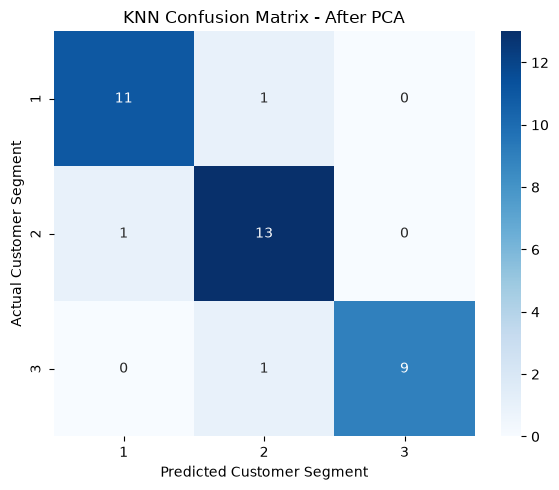

KNN Test Performance Before and After PCA (weighted averages)
Method     KNN Before PCA  KNN After PCA
Metric                                  
Accuracy            0.972          0.917
Precision           0.975          0.920
Recall              0.972          0.917
F1-score            0.972          0.917


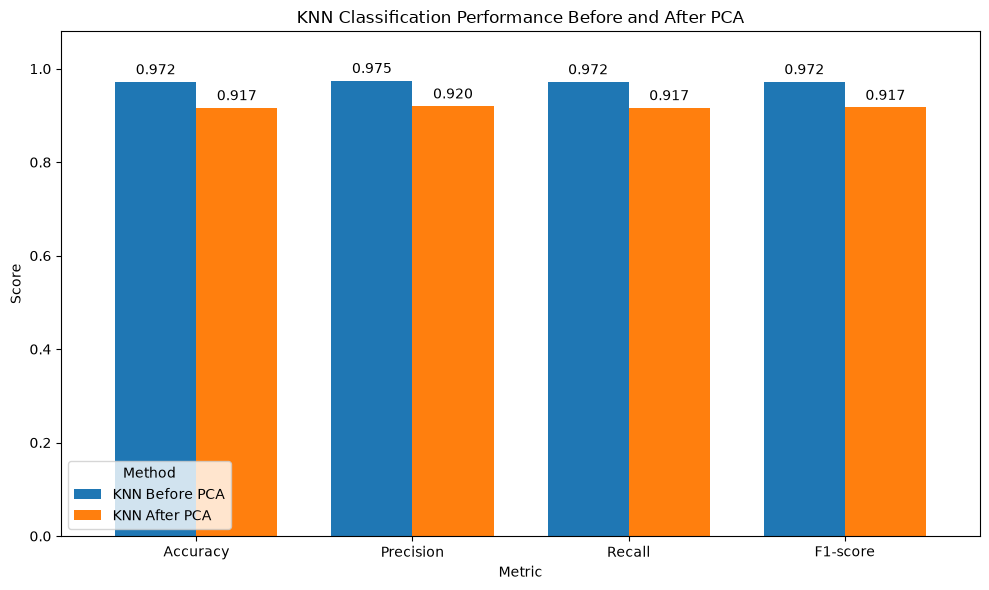

In [22]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Keep the confusion matrix for KNN after PCA.
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_test_pred, labels=classes),
            annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.title("KNN Confusion Matrix - After PCA")
plt.xlabel("Predicted Customer Segment")
plt.ylabel("Actual Customer Segment")
plt.tight_layout()
plt.show()

# Weighted averaging accounts for the number of test samples in each class.
# Both models are evaluated on the same test samples.
def get_scores(actual, predicted):
    return [
        accuracy_score(actual, predicted),
        precision_score(actual, predicted, average="weighted", zero_division=0),
        recall_score(actual, predicted, average="weighted", zero_division=0),
        f1_score(actual, predicted, average="weighted", zero_division=0),
    ]

metrics_df = pd.DataFrame({
    "KNN Before PCA": get_scores(y_test, test_pred_before),
    "KNN After PCA": get_scores(y_test, y_test_pred),
}, index=["Accuracy", "Precision", "Recall", "F1-score"])
metrics_df.index.name = "Metric"
metrics_df.columns.name = "Method"
print("KNN Test Performance Before and After PCA (weighted averages)")
print(metrics_df.round(3).to_string())

ax = metrics_df.plot(kind="bar", figsize=(10, 6),
                     color=["#1f77b4", "#ff7f0e"], width=0.75)
ax.set_title("KNN Classification Performance Before and After PCA")
ax.set_xlabel("Metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.08)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Method", loc="lower left")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)
plt.tight_layout()
plt.show()
